# **Pattern Recognition: Combined Notebook**

### **Imports**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### **Dataset Paths**

In [2]:
import os

# Folder that holds mnist, image_features, tdigits and synthetic.
# Relative to this notebook, or use a full path, e.g. r"C:\Users\you\Desktop\Assignment"
DATA_DIR = "Assignment"
TIDIGITS_DIR = "tdigits"   # change to "tidigits" if that is the folder's name

for name in ["synthetic", "image_features", "mnist", TIDIGITS_DIR]:
    print(f"{name:15}", "found" if os.path.isdir(os.path.join(DATA_DIR, name)) else "NOT FOUND",
          "->", os.path.abspath(os.path.join(DATA_DIR, name)))


synthetic       NOT FOUND -> c:\Users\user\Documents\Assignment\Assignment\synthetic
image_features  NOT FOUND -> c:\Users\user\Documents\Assignment\Assignment\image_features
mnist           NOT FOUND -> c:\Users\user\Documents\Assignment\Assignment\mnist
tdigits         NOT FOUND -> c:\Users\user\Documents\Assignment\Assignment\tdigits


In [3]:
def plot_pca_2d(X, y):
    pca = PCA(k=2).fit(X)
    points = pca.transform(X)

    plt.figure(figsize=(7, 5))
    for label in np.unique(y):
        selected = y == label
        plt.scatter(points[selected, 0], points[selected, 1],
                    s=10, alpha=0.5, edgecolors="none", label=str(label))
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("Training data (2D PCA)")
    plt.legend(title="Class")
    plt.tight_layout()
    plt.show()

## **Library Code**

### **K-Means**

In [4]:
class KMeans:
    def __init__(self, K=3):
        self.K = K
        self.centers = None

    def fit(self, X):
        # Deterministic start: sort points along the direction of largest
        # variance and take K evenly spaced points from that ordering.
        centered = X - X.mean(axis=0)
        _, _, directions = np.linalg.svd(centered, full_matrices=False)
        order = np.argsort(centered @ directions[0], kind="stable")
        positions = ((np.arange(self.K) + 0.5) * len(X) / self.K).astype(int)
        self.centers = X[order[positions]].astype(float)

        for _ in range(100):
            labels = self.predict(X)
            new_centers = self.centers.copy()

            for k in range(self.K):
                points = X[labels == k]
                if len(points) > 0:
                    new_centers[k] = points.mean(axis=0)

            converged = np.max(np.abs(self.centers - new_centers)) < 1e-6
            self.centers = new_centers
            if converged:
                break

        return self

    def predict(self, X):
        if self.centers is None:
            raise ValueError("Call fit() before predict().")

        labels = []
        for point in X:
            distances = [np.sum((point - center) ** 2) for center in self.centers]
            labels.append(np.argmin(distances))

        return np.array(labels, dtype=int)


### **GMM**

In [5]:
class GMM:
    def __init__(self, K=3, reg=1e-6, max_iter=100, tol=1e-6):
        self.K = K
        self.reg = reg
        self.max_iter = max_iter
        self.tol = tol
        self.weights = None
        self.means = None
        self.covariances = None
        self.log_likelihoods = []

    def component_scores(self, X):
        n, d = X.shape
        scores = np.zeros((n, self.K))

        for k in range(self.K):
            difference = X - self.means[k]
            eigenvalues = np.linalg.eigvalsh(self.covariances[k])
            if np.any(eigenvalues <= 0):
                raise ValueError("Covariance must be positive definite. Try a larger reg.")
            # Log determinant = sum of the logs of the eigenvalues.
            log_det = np.log(eigenvalues).sum()
            inverse_covariance = np.linalg.inv(self.covariances[k])
            # Quadratic term: (x - mean).T @ inverse_covariance @ (x - mean)
            d_squared = np.sum((difference @ inverse_covariance) * difference, axis=1)
            scores[:, k] = np.log(self.weights[k]) - 0.5 * (
                d * np.log(2 * np.pi) + log_det + d_squared
            )

        return scores

    def score_samples(self, X):
        # log of the mixture density, calculated without tiny exponentials
        scores = self.component_scores(X)
        largest = scores.max(axis=1)
        return largest + np.log(np.exp(scores - largest[:, None]).sum(axis=1))

    def fit(self, X):
        n, d = X.shape
        model = KMeans(K=self.K)
        model.fit(X)
        labels = model.predict(X)

        self.means = model.centers.copy()
        self.weights = np.zeros(self.K)
        self.covariances = np.zeros((self.K, d, d))
        self.log_likelihoods = []

        for k in range(self.K):
            points = X[labels == k]
            if len(points) == 0:
                raise ValueError("K-means produced an empty component. Try another K.")
            difference = points - self.means[k]
            self.weights[k] = len(points) / n
            self.covariances[k] = difference.T @ difference / len(points)
            self.covariances[k] += self.reg * np.eye(d)

        for _ in range(self.max_iter):
            # E-step: soft membership of each point in each component
            scores = self.component_scores(X)
            scores -= scores.max(axis=1, keepdims=True)
            responsibilities = np.exp(scores)
            responsibilities /= responsibilities.sum(axis=1, keepdims=True)

            # M-step: update weights, means, and covariances
            counts = responsibilities.sum(axis=0)
            if np.any(counts < 1e-10):
                raise ValueError("A component has no effective points. Try a smaller K.")
            self.weights = counts / n
            self.means = responsibilities.T @ X / counts[:, None]

            for k in range(self.K):
                difference = X - self.means[k]
                weighted_difference = responsibilities[:, k, None] * difference
                self.covariances[k] = difference.T @ weighted_difference / counts[k]
                self.covariances[k] += self.reg * np.eye(d)

            log_likelihood = self.score_samples(X).mean()
            self.log_likelihoods.append(log_likelihood)
            if len(self.log_likelihoods) > 1:
                change = self.log_likelihoods[-1] - self.log_likelihoods[-2]
                if abs(change) < self.tol:
                    break

        return self


### **KNN**

In [6]:
class KNN:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X = X
        self.y = y
        return self

    def predict(self, X):
        predictions = []
        for point in X:
            distances = np.sum((self.X - point) ** 2, axis=1)
            nearest = np.argsort(distances)[:self.k]
            labels, counts = np.unique(self.y[nearest], return_counts=True)
            predictions.append(labels[np.argmax(counts)])
        return np.array(predictions)


### **LDA**

In [7]:
class LDA:
    def __init__(self, reg=1e-3):
        self.reg = reg

    def fit(self, X, y):
        self.classes = np.unique(y)
        n, d = X.shape
        means = []
        priors = []
        covariance = np.zeros((d, d))

        for label in self.classes:
            samples = X[y == label]
            mean = samples.mean(axis=0)
            means.append(mean)
            priors.append(len(samples) / n)
            difference = samples - mean
            covariance += difference.T @ difference

        self.means = np.array(means)
        self.covariance = covariance / n + self.reg * np.eye(d)
        self.weights = np.linalg.solve(self.covariance, self.means.T).T
        self.bias = -0.5 * np.sum(self.means * self.weights, axis=1) + np.log(priors)
        return self

    def predict(self, X):
        scores = X @ self.weights.T + self.bias
        return self.classes[np.argmax(scores, axis=1)]


### **PCA**

In [8]:
class PCA:
    def __init__(self, k):
        self.k = k

    def fit(self, X):
        if not 1 <= self.k <= X.shape[1]:
            raise ValueError("k must be between 1 and the number of features.")
        self.mean = X.mean(axis=0)
        centered = X - self.mean
        covariance = centered.T @ centered / len(X)
        eigenvalues, eigenvectors = np.linalg.eigh(covariance)
        order = np.argsort(eigenvalues)[::-1]
        self.components = eigenvectors[:, order[:self.k]]
        return self

    def transform(self, X):
        return (X - self.mean) @ self.components


### **SVM**

In [9]:
class SVM:
    def __init__(self, sigma=None, tol=1e-3, max_iter=100000):
        self.sigma = sigma
        self.tol = tol
        self.max_iter = max_iter

    def kernel(self, X, Z):
        distances = (np.sum(X ** 2, axis=1)[:, None]
                     + np.sum(Z ** 2, axis=1) - 2 * X @ Z.T)
        np.maximum(distances, 0, out=distances)
        distances *= -1 / (2 * self.width ** 2)
        np.exp(distances, out=distances)
        return distances

    def fit_binary(self, X, y, K):
        alpha = np.zeros(len(y))
        gradient = y.astype(float).copy()

        for _ in range(self.max_iter):
            upper = (y == 1) | (alpha > 0)
            lower = (y == -1) | (alpha > 0)
            i = np.argmax(np.where(upper, gradient, -np.inf))
            j = np.argmin(np.where(lower, gradient, np.inf))
            gap = gradient[i] - gradient[j]
            if gap <= self.tol:
                gradient = y - K @ (alpha * y)
                if gradient[upper].max() - gradient[lower].min() <= self.tol:
                    break
                continue

            limit = min(alpha[i] if y[i] == -1 else np.inf,
                        alpha[j] if y[j] == 1 else np.inf)
            curvature = K[i, i] + K[j, j] - 2 * K[i, j]
            if curvature <= 0:
                if np.isinf(limit):
                    raise ValueError("Hard-margin separation failed at this kernel width.")
                step = limit
            else:
                step = min(gap / curvature, limit)
            alpha[i] += y[i] * step
            alpha[j] -= y[j] * step
            gradient -= step * (K[:, i] - K[:, j])

        gradient = y - K @ (alpha * y)
        upper = (y == 1) | (alpha > 0)
        lower = (y == -1) | (alpha > 0)
        gap = gradient[upper].max() - gradient[lower].min()
        support = alpha > 0
        bias = gradient[support].mean()
        return X[support], alpha[support] * y[support], bias, gap

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes = np.unique(y)
        self.width = self.sigma
        if self.width is None:
            self.width = np.sqrt(X.var(axis=0).sum()) / 2
        if self.width <= 0:
            raise ValueError("sigma must be positive.")
        self.models = []
        self.gaps = []

        K = self.kernel(X, X)
        np.fill_diagonal(K, 1.0)
        targets = self.classes if len(self.classes) > 2 else self.classes[:1]
        for label in targets:
            labels = np.where(y == label, 1, -1)
            points, coefficients, bias, gap = self.fit_binary(X, labels, K)
            self.models.append((points, coefficients, bias))
            self.gaps.append(gap)
        self.converged = all(gap <= self.tol for gap in self.gaps)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        scores = np.column_stack([self.kernel(X, points) @ coefficients + bias
                                  for points, coefficients, bias in self.models])
        if len(self.classes) == 2:
            return np.where(scores[:, 0] >= 0, self.classes[0], self.classes[1])
        return self.classes[np.argmax(scores, axis=1)]


### **DTW**

In [10]:
def dtw(x, y, window=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if x.ndim == 1:
        x = x[:, None]
    if y.ndim == 1:
        y = y[:, None]
    n, m = len(x), len(y)
    if n == 0 or m == 0 or x.shape[1] != y.shape[1]:
        raise ValueError("Use nonempty sequences with matching feature counts.")
    width = max(n, m) if window is None else max(window, abs(n - m))
    cost = np.full((n + 1, m + 1), np.inf)
    cost[0, 0] = 0

    for i in range(n):
        distances = np.sqrt(np.sum((y - x[i]) ** 2, axis=1))
        for j in range(max(0, i - width), min(m, i + width + 1)):
            cost[i + 1, j + 1] = distances[j] + min(
                cost[i, j], cost[i, j + 1], cost[i + 1, j])
    return cost[n, m]


class DTW:
    def __init__(self, references_per_class=10, window=25):
        self.references_per_class = references_per_class
        self.window = window

    def fit(self, sequences, y):
        y = np.asarray(y)
        self.indices = []
        for label in np.unique(y):
            candidates = np.flatnonzero(y == label)
            count = min(self.references_per_class, len(candidates))
            # Deterministic references: evenly spaced through the class.
            positions = np.linspace(0, len(candidates) - 1, count).round().astype(int)
            self.indices.extend(candidates[positions])
        self.sequences = [sequences[i] for i in self.indices]
        self.y = y[self.indices]
        return self

    def predict(self, sequences):
        predictions = []
        for sequence in sequences:
            distances = [dtw(sequence, reference, self.window)
                         for reference in self.sequences]
            predictions.append(self.y[np.argmin(distances)])
        return np.array(predictions)


## **Synthetic Data**

### **Load Data**

In [14]:
import os
print("Notebook is running in:", os.getcwd())
print("Contents here:", os.listdir("."))

if os.path.isdir(DATA_DIR):
    for name in os.listdir(DATA_DIR):
        full = os.path.join(DATA_DIR, name)
        if os.path.isdir(full):
            print(name, "->", os.listdir(full)[:10])
else:
    print(DATA_DIR, "is not in this folder")

Notebook is running in: c:\Users\user\Documents\Assignment
Contents here: ['AI5707_Assignment_8.pdf', 'Assignment', 'combined_standalone.ipynb', 'Kary', 'src']
image_features -> ['test_data.csv', 'test_label.csv', 'train_data.csv', 'train_label.csv', 'val_data.csv', 'val_label.csv']
mnist -> ['dev', 'test', 'train']
synthetic -> ['data.pkl', 'data_plot.png', 'synthetic_data.py']
tidigits -> ['Data', 'feature_extraction.py', 'mapping.py']


In [15]:
import pickle

with open(os.path.join(DATA_DIR, "synthetic", "data.pkl"), "rb") as file:
    data = pickle.load(file)
X = data["x"]
y = data["y"]

print(X.shape)
print(y.shape)

(20000, 16)
(20000,)


### **Shuffle and Split**

In [16]:
indices = np.arange(len(y))
# Deterministic stratified split: within each class, every 5 consecutive
# samples go 3 -> train, 1 -> validation, 1 -> test (60/20/20).
slot = np.zeros(len(y), dtype=int)
for label in np.unique(y):
    members = indices[y == label]
    slot[members] = np.arange(len(members)) % 5

train_indices = indices[slot < 3]
val_indices = indices[slot == 3]
test_indices = indices[slot == 4]

X_train = X[train_indices]
y_train = y[train_indices]
X_val = X[val_indices]
y_val = y[val_indices]
X_test = X[test_indices]
y_test = y[test_indices]


In [17]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [0 1]
Train: (12000, 16)
Validation: (4000, 16)
Test: (4000, 16)


### **2D PCA Visualization**

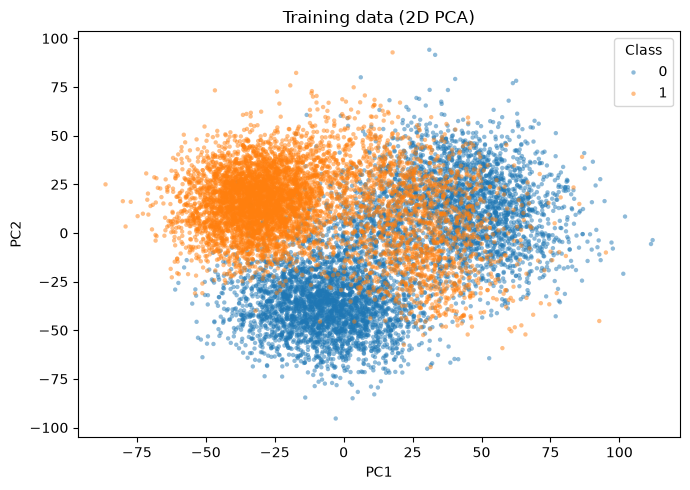

In [18]:
plot_pca_2d(X_train, y_train)


### **GMM**

In [19]:
models = []
priors = []
for label in classes:
    samples = X_train[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 4
Class 1 EM iterations: 44


In [20]:
val_scores = np.column_stack([model.score_samples(X_val) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [21]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 0.99975
Test accuracy: 0.99975
Test confusion matrix:
 [[2000    0]
 [   1 1999]]


### **KNN**

In [22]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)


In [23]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.99625
Test accuracy: 0.99775
Test confusion matrix:
 [[1998    2]
 [   7 1993]]


### **LDA**

In [24]:
lda = LDA()
lda.fit(X_train, y_train)
lda_val_predictions = lda.predict(X_val)
lda_test_predictions = lda.predict(X_test)


In [25]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.8905
Test accuracy: 0.89175
Test confusion matrix:
 [[1785  215]
 [ 218 1782]]


### **SVM**

In [26]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 1
Gaussian sigma: 38.95363420356627
Converged: True
Largest KKT gap: 0.0009950621625702816


In [27]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.997
Test accuracy: 0.99825
Test confusion matrix:
 [[1996    4]
 [   3 1997]]


### **PCA**

In [28]:
K = 8
pca = PCA(k=K)
pca.fit(X_train)
X_train_pca = pca.transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (12000, 8)
Validation: (4000, 8)
Test: (4000, 8)


### **GMM with PCA**

In [29]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 16
Class 1 EM iterations: 3


In [30]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [31]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.986
Test accuracy: 0.9875
Test confusion matrix:
 [[1977   23]
 [  27 1973]]


### **KNN with PCA**

In [32]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [33]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.97575
Test accuracy: 0.981
Test confusion matrix:
 [[1977   23]
 [  53 1947]]


### **LDA with PCA**

In [34]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [35]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.85775
Test accuracy: 0.8675
Test confusion matrix:
 [[1750  250]
 [ 280 1720]]


### **SVM with PCA**

In [36]:
svm_pca = SVM(max_iter=1000000)
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 1
Gaussian sigma: 33.56529025531221
Converged: True
Largest KKT gap: 0.0009807014128853098


In [37]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.965
Test accuracy: 0.97025
Test confusion matrix:
 [[1934   66]
 [  53 1947]]


### **Accuracy Comparison**

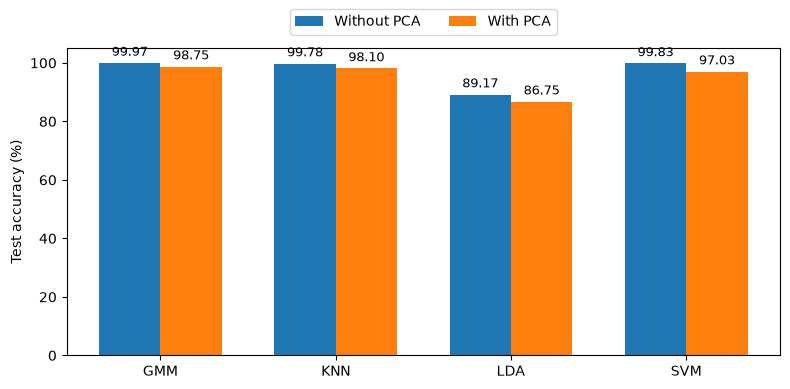

In [38]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()


## **D2 / Image Features**

### **Load Data**

In [39]:
def load_split(split):
    X = np.loadtxt(os.path.join(DATA_DIR, "image_features", f"{split}_data.csv"), delimiter=",")
    y = np.loadtxt(os.path.join(DATA_DIR, "image_features", f"{split}_label.csv"), delimiter=",").astype(int)
    return X, y


X_train, y_train = load_split("train")
X_val, y_val = load_split("val")
X_test, y_test = load_split("test")


In [40]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [0 1 2 3 4]
Train: (2000, 36)
Validation: (500, 36)
Test: (500, 36)


### **2D PCA Visualization**

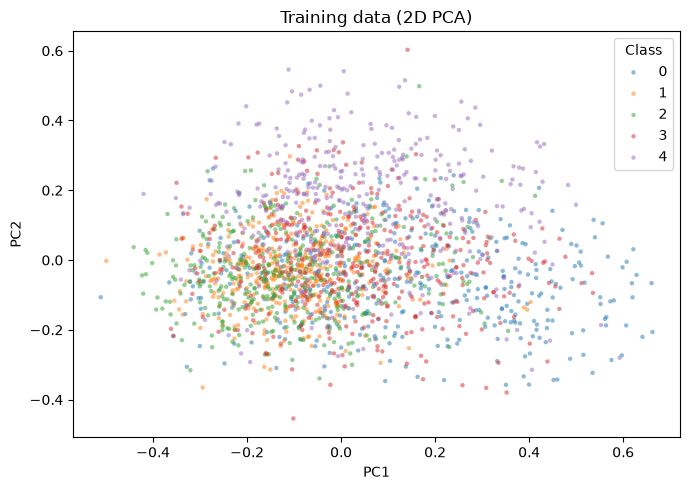

In [41]:
plot_pca_2d(X_train, y_train)


### **GMM**

In [42]:
models = []
priors = []
for label in classes:
    samples = X_train[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 21
Class 1 EM iterations: 43
Class 2 EM iterations: 27
Class 3 EM iterations: 29
Class 4 EM iterations: 19


In [43]:
val_scores = np.column_stack([model.score_samples(X_val) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [44]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 0.452
Test accuracy: 0.464
Test confusion matrix:
 [[44 21 11 16  8]
 [ 8 61 20  7  4]
 [11 28 40 15  6]
 [17 24 13 32 14]
 [12 15  3 15 55]]


### **KNN**

In [45]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)


In [46]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.436
Test accuracy: 0.448
Test confusion matrix:
 [[43 23 15 15  4]
 [ 7 68 15  8  2]
 [11 40 38  5  6]
 [22 34 15 17 12]
 [ 8 19 10  5 58]]


### **LDA**

In [47]:
lda = LDA()
lda.fit(X_train, y_train)
lda_val_predictions = lda.predict(X_val)
lda_test_predictions = lda.predict(X_test)


In [48]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.5
Test accuracy: 0.504
Test confusion matrix:
 [[42 18 19 17  4]
 [ 7 64 18 10  1]
 [13 19 49  9 10]
 [17 24 15 30 14]
 [ 4 13  6 10 67]]


### **SVM**

In [49]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 5
Gaussian sigma: 0.24726843901293377
Converged: True
Largest KKT gap: 0.0009969668115156205


In [50]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.466
Test accuracy: 0.492
Test confusion matrix:
 [[50 17 11 12 10]
 [ 7 62 17  9  5]
 [ 9 23 43 14 11]
 [21 23 14 30 12]
 [11 16  2 10 61]]


### **PCA**

In [51]:
K = 18
pca = PCA(k=K)
pca.fit(X_train)
X_train_pca = pca.transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (2000, 18)
Validation: (500, 18)
Test: (500, 18)


### **GMM with PCA**

In [52]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 44
Class 1 EM iterations: 77
Class 2 EM iterations: 56
Class 3 EM iterations: 66
Class 4 EM iterations: 16


In [53]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [54]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.476
Test accuracy: 0.48
Test confusion matrix:
 [[43 18 12 20  7]
 [11 55 26  8  0]
 [ 7 25 43 12 13]
 [20 22 15 31 12]
 [ 6 10  4 12 68]]


### **KNN with PCA**

In [55]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [56]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.452
Test accuracy: 0.434
Test confusion matrix:
 [[42 29 11 15  3]
 [ 9 62 19  8  2]
 [ 9 33 42  7  9]
 [18 39 18 13 12]
 [ 5 23  5  9 58]]


### **LDA with PCA**

In [57]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [58]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.496
Test accuracy: 0.452
Test confusion matrix:
 [[40 17 21 18  4]
 [ 9 50 29 12  0]
 [11 25 46  8 10]
 [15 25 19 25 16]
 [ 5 10  6 14 65]]


### **SVM with PCA**

In [59]:
svm_pca = SVM()
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 5
Gaussian sigma: 0.2238641797900042
Converged: True
Largest KKT gap: 0.0009898517398241324


In [60]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.458
Test accuracy: 0.468
Test confusion matrix:
 [[47 17 10 20  6]
 [13 52 17 12  6]
 [ 9 19 47 13 12]
 [19 19 18 28 16]
 [ 8 17  6  9 60]]


### **Accuracy Comparison**

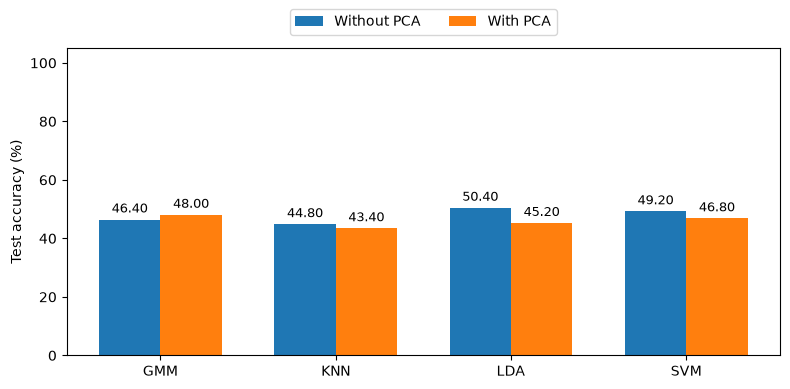

In [61]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()


## **MNIST**

### **Load Data**

In [63]:
import os
from PIL import Image


def load_images(folder):
    images = []
    labels = []
    for digit in [0, 1, 4]:
        digit_folder = os.path.join(folder, str(digit))
        for filename in sorted(os.listdir(digit_folder)):
            if filename.endswith(".png"):
                with Image.open(os.path.join(digit_folder, filename)) as image:
                    pixels = np.array(image.convert("L"), dtype=float)
                    images.append(pixels.ravel() / 255.0)
                    labels.append(digit)
    return np.array(images), np.array(labels)


X_train, y_train = load_images(os.path.join(DATA_DIR, "mnist", "train"))
X_val, y_val = load_images(os.path.join(DATA_DIR, "mnist", "dev"))
X_test, y_test = load_images(os.path.join(DATA_DIR, "mnist", "test"))


In [64]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [0 1 4]
Train: (14799, 784)
Validation: (3708, 784)
Test: (3097, 784)


### **2D PCA Visualization**

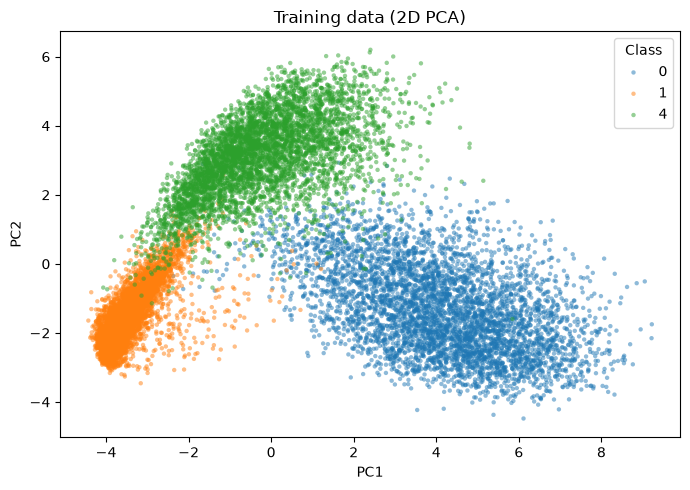

In [65]:
plot_pca_2d(X_train, y_train)

### **GMM**

In [66]:
models = []
priors = []
for label in classes:
    samples = X_train[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 19
Class 1 EM iterations: 49
Class 4 EM iterations: 26


In [67]:
val_scores = np.column_stack([model.score_samples(X_val) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [68]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 0.9846278317152104
Test accuracy: 0.9903132063287052
Test confusion matrix:
 [[ 979    0    1]
 [  15 1116    4]
 [  10    0  972]]


### **KNN**

In [69]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)

In [70]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.9956850053937433
Test accuracy: 0.996125282531482
Test confusion matrix:
 [[ 978    2    0]
 [   0 1135    0]
 [   3    7  972]]


### **LDA**

In [71]:
lda = LDA()
lda.fit(X_train, y_train)
lda_val_predictions = lda.predict(X_val)
lda_test_predictions = lda.predict(X_test)


In [72]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.9857065803667745
Test accuracy: 0.9922505650629642
Test confusion matrix:
 [[ 970    2    8]
 [   2 1130    3]
 [   1    8  973]]


### **SVM**

In [73]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 3
Gaussian sigma: 3.583887295559391
Converged: True
Largest KKT gap: 0.0009971561341465263


In [74]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.9967637540453075
Test accuracy: 0.998708427510494
Test confusion matrix:
 [[ 978    1    1]
 [   0 1134    1]
 [   1    0  981]]


### **PCA**

In [75]:
K = 50
pca = PCA(k=K)
pca.fit(X_train)
X_train_pca = pca.transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (14799, 50)
Validation: (3708, 50)
Test: (3097, 50)


### **GMM with PCA**

In [76]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 22
Class 1 EM iterations: 42
Class 4 EM iterations: 100
Iteration limit reached; convergence is not guaranteed.


In [77]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [78]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.9956850053937433
Test accuracy: 0.9983855343881175
Test confusion matrix:
 [[ 980    0    0]
 [   1 1132    2]
 [   0    2  980]]


### **KNN with PCA**

In [79]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [80]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.9956850053937433
Test accuracy: 0.9974168550209881
Test confusion matrix:
 [[ 977    2    1]
 [   0 1135    0]
 [   2    3  977]]


### **LDA with PCA**

In [81]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [82]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.9870550161812298
Test accuracy: 0.9951566031643526
Test confusion matrix:
 [[ 971    1    8]
 [   0 1135    0]
 [   1    5  976]]


### **SVM with PCA**

In [83]:
svm_pca = SVM()
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 3
Gaussian sigma: 3.3586350553411775
Converged: True
Largest KKT gap: 0.0009950706378640817


In [84]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.9970334412081985
Test accuracy: 0.9990313206328705
Test confusion matrix:
 [[ 977    2    1]
 [   0 1135    0]
 [   0    0  982]]


### **Accuracy Comparison**

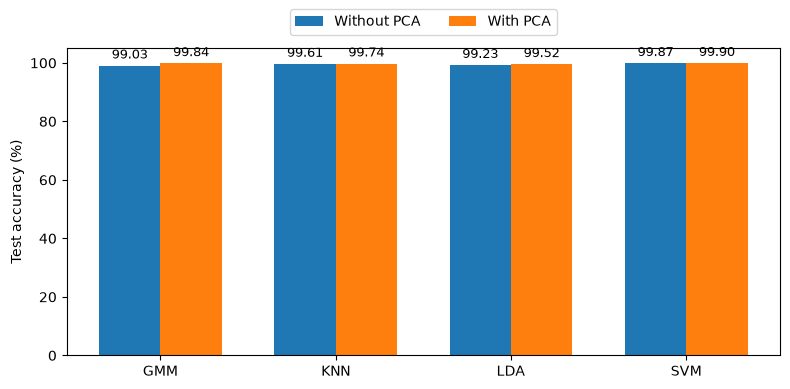

In [85]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()


## **TIDIGITS**

### **Load Data**

In [89]:
sequences = []
labels = []
for digit in [7, 1, 8]:
    with np.load(os.path.join(DATA_DIR, TIDIGITS_DIR, f"{digit}.npz")) as data:
        for key in data.files:
            sequences.append(data[key])
            labels.append(digit)

y = np.array(labels)

print("Recordings:", len(sequences))
print("Labels:", y.shape)


Recordings: 1350
Labels: (1350,)


### **Shuffle and Split**

In [90]:
indices = np.arange(len(y))
# Deterministic stratified split: within each class, every 5 consecutive
# samples go 3 -> train, 1 -> validation, 1 -> test (60/20/20).
slot = np.zeros(len(y), dtype=int)
for label in np.unique(y):
    members = indices[y == label]
    slot[members] = np.arange(len(members)) % 5

train_indices = indices[slot < 3]
val_indices = indices[slot == 3]
test_indices = indices[slot == 4]

y_train = y[train_indices]
y_val = y[val_indices]
y_test = y[test_indices]


### **Sequence Length Distribution**

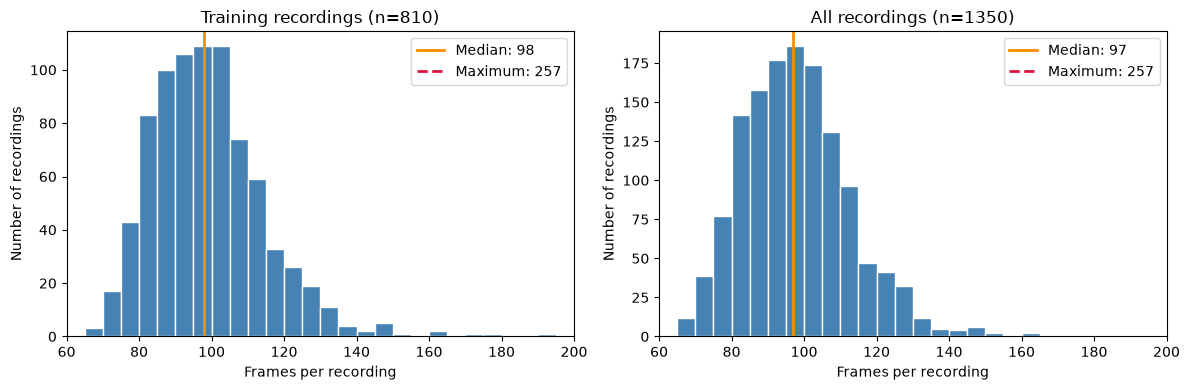

In [91]:
lengths = np.array([len(s) for s in sequences])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, values, title in zip(axes, [lengths[train_indices], lengths],
                            ["Training recordings", "All recordings"]):
    ax.hist(values, bins=np.arange(60, 201, 5), color="steelblue", edgecolor="white")
    ax.axvline(np.median(values), color="darkorange", linewidth=2,
               label=f"Median: {np.median(values):.0f}")
    ax.axvline(values.max(), color="crimson", linestyle="--", linewidth=2,
               label=f"Maximum: {values.max()}")
    ax.set_title(f"{title} (n={len(values)})")
    ax.set_xlabel("Frames per recording")
    ax.set_ylabel("Number of recordings")
    ax.set_xlim(60, 200)
    ax.legend()
plt.tight_layout()
plt.show()


In [92]:
# raw_train_sequences = [sequences[i] for i in train_indices]
# raw_val_sequences = [sequences[i] for i in val_indices]
# raw_test_sequences = [sequences[i] for i in test_indices]
# frame_length = int(np.quantile([len(s) for s in raw_train_sequences], q=0.95))
# print(frame_length)

### **Padding**

In [93]:
raw_train_sequences = [sequences[i] for i in train_indices]
raw_val_sequences = [sequences[i] for i in val_indices]
raw_test_sequences = [sequences[i] for i in test_indices]
frame_length = int(np.median([len(s) for s in raw_train_sequences]))
# frame_length = int(np.quantile([len(s) for s in raw_train_sequences], q=0.95))



def pad_sequences(recordings):
    padded = []
    for recording in recordings:
        values = np.zeros((frame_length, recording.shape[1]))
        count = min(len(recording), frame_length)
        values[:count] = recording[:count]
        padded.append(values)
    return padded


train_sequences = pad_sequences(raw_train_sequences)
val_sequences = pad_sequences(raw_val_sequences)
test_sequences = pad_sequences(raw_test_sequences)
X_train = np.array(train_sequences).reshape(len(train_sequences), -1)
X_val = np.array(val_sequences).reshape(len(val_sequences), -1)
X_test = np.array(test_sequences).reshape(len(test_sequences), -1)
print("Target frames:", frame_length)


Target frames: 98


In [94]:
X_train.shape

(810, 3822)

In [95]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [1 7 8]
Train: (810, 3822)
Validation: (270, 3822)
Test: (270, 3822)


### **Training Coordinates for GMM and LDA**

In [96]:
feature_mean = X_train.mean(axis=0)
_, _, vectors = np.linalg.svd(X_train - feature_mean, full_matrices=False)
basis = vectors.T
X_train_gaussian = (X_train - feature_mean) @ basis
X_val_gaussian = (X_val - feature_mean) @ basis
X_test_gaussian = (X_test - feature_mean) @ basis
print("All training directions retained:", X_train_gaussian.shape)


All training directions retained: (810, 810)


### **2D PCA Visualization**

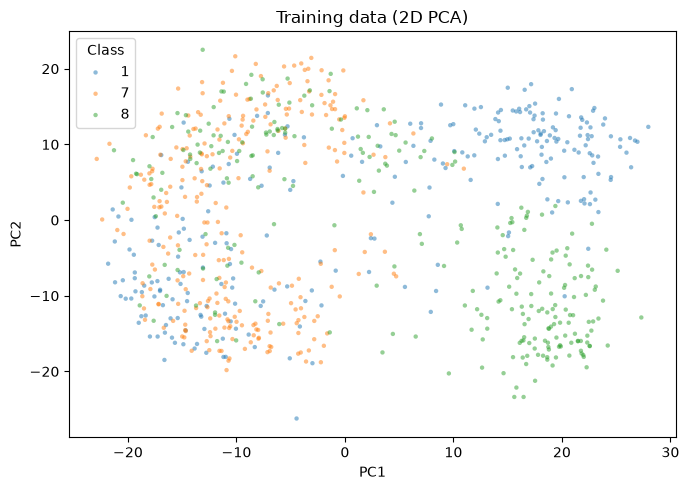

In [97]:
plot_pca_2d(X_train_gaussian, y_train)


### **GMM**

In [98]:
models = []
priors = []
for label in classes:
    samples = X_train_gaussian[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train_gaussian))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 1 EM iterations: 2
Class 7 EM iterations: 2
Class 8 EM iterations: 2


In [99]:
val_scores = np.column_stack([model.score_samples(X_val_gaussian) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test_gaussian) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [100]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 0.9592592592592593
Test accuracy: 0.9555555555555556
Test confusion matrix:
 [[85  4  1]
 [ 1 88  1]
 [ 0  5 85]]


### **KNN**

In [101]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)


In [102]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.9851851851851852
Test accuracy: 0.9666666666666667
Test confusion matrix:
 [[89  1  0]
 [ 2 87  1]
 [ 1  4 85]]


### **LDA**

In [103]:
lda = LDA()
lda.fit(X_train_gaussian, y_train)
lda_val_predictions = lda.predict(X_val_gaussian)
lda_test_predictions = lda.predict(X_test_gaussian)


In [104]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.8666666666666667
Test accuracy: 0.9037037037037037
Test confusion matrix:
 [[82  3  5]
 [ 4 84  2]
 [ 6  6 78]]


### **SVM**

In [105]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 3
Gaussian sigma: 29.73099793549903
Converged: True
Largest KKT gap: 0.000998604259268232


In [106]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.9259259259259259
Test accuracy: 0.9444444444444444
Test confusion matrix:
 [[83  6  1]
 [ 1 88  1]
 [ 0  6 84]]


### **PCA**

In [107]:
K = 39
pca = PCA(k=K)
pca.fit(X_train_gaussian)
X_train_pca = pca.transform(X_train_gaussian)
X_val_pca = pca.transform(X_val_gaussian)
X_test_pca = pca.transform(X_test_gaussian)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (810, 39)
Validation: (270, 39)
Test: (270, 39)


### **GMM with PCA**

In [108]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 1 EM iterations: 2
Class 7 EM iterations: 2
Class 8 EM iterations: 2


In [109]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [110]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.9666666666666667
Test accuracy: 0.9666666666666667
Test confusion matrix:
 [[88  1  1]
 [ 3 87  0]
 [ 0  4 86]]


### **KNN with PCA**

In [111]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [112]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.9814814814814815
Test accuracy: 0.9703703703703703
Test confusion matrix:
 [[88  2  0]
 [ 3 87  0]
 [ 0  3 87]]


### **LDA with PCA**

In [113]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [114]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.8555555555555555
Test accuracy: 0.8888888888888888
Test confusion matrix:
 [[78  7  5]
 [ 3 85  2]
 [ 6  7 77]]


### **SVM with PCA**

In [115]:
svm_pca = SVM()
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 3
Gaussian sigma: 19.962281925028684
Converged: True
Largest KKT gap: 0.000993840330145268


In [116]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.9740740740740741
Test accuracy: 0.9666666666666667
Test confusion matrix:
 [[89  1  0]
 [ 2 88  0]
 [ 0  6 84]]


### **Accuracy Comparison**

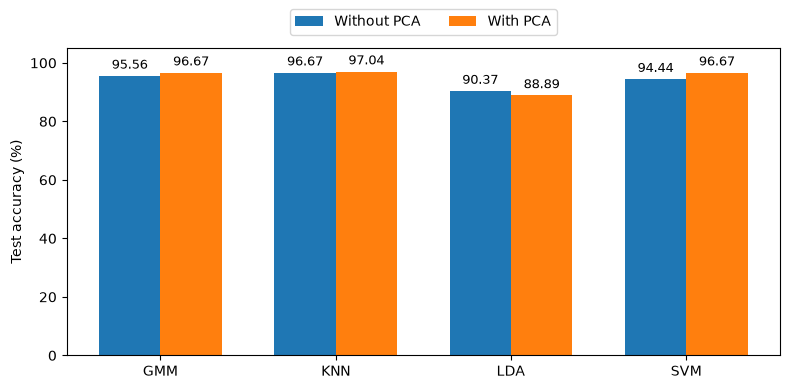

In [117]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()
